In [1]:
# Core scverse libraries
from __future__ import annotations

import anndata as ad

# Data retrieval
import pooch
import scanpy as sc

AnnData est une bibliothèque (et une structure de données) Python indépendante, conçue spécifiquement pour gérer des matrices de données tabulaires annotées à grande échelle, avec un focus particulier sur la génomique et le single-cell.

pooch est un utilitaire de téléchargement et de gestion de cache.

scanpy est la bibliothèque principale de traitement et d'analyse de données single-cell.

In [2]:
import sys
print(sys.executable)

/home/amalet/venvs/scanpy/bin/python3


In [4]:
sc.set_figure_params(dpi=50, facecolor="white")

In [5]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

In [7]:
samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}
adatas = {}

for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()
print(adata.obs["sample"].value_counts())
adata

/home/amalet/venvs/scanpy/lib64/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/home/amalet/venvs/scanpy/lib64/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/tmp/ipykernel_12614/3491096135.py:13: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = ad.concat(adatas, label="sample")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'
    layers: None (.X)

### Mitochondrial / Ribosomal / Hemoglobin genes
* **Mitochondrie :** Contrôle la santé des cellules, chercher des signes d'apoptose.
* **Ribosomes :** Chercher des signes d'activité traductionnelle, métabolique.
* **Hémoglobine :** Détection de contamination sanguine.


In [12]:
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes Ribosomal Protein Small subunit, Ribosomal Protein Large subunit
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes. La regex "^HB[^(P)]": "Trouve les gènes commençant par HB, suivis de n'importe quel caractère, à condition que ce caractère ne soit pas un P".
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

Rappel sur les [  ]: Tout y est considéré par défaut comme un simple caractère, sauf de très rares exceptions (comme le tiret pour les plages a-z ou le ^ pour inverser la sélection).

Adding QC variables to the adata dataset with scanpy sc.pp.calculate_qc_metrics().

In [13]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)  # pp: pre-processing

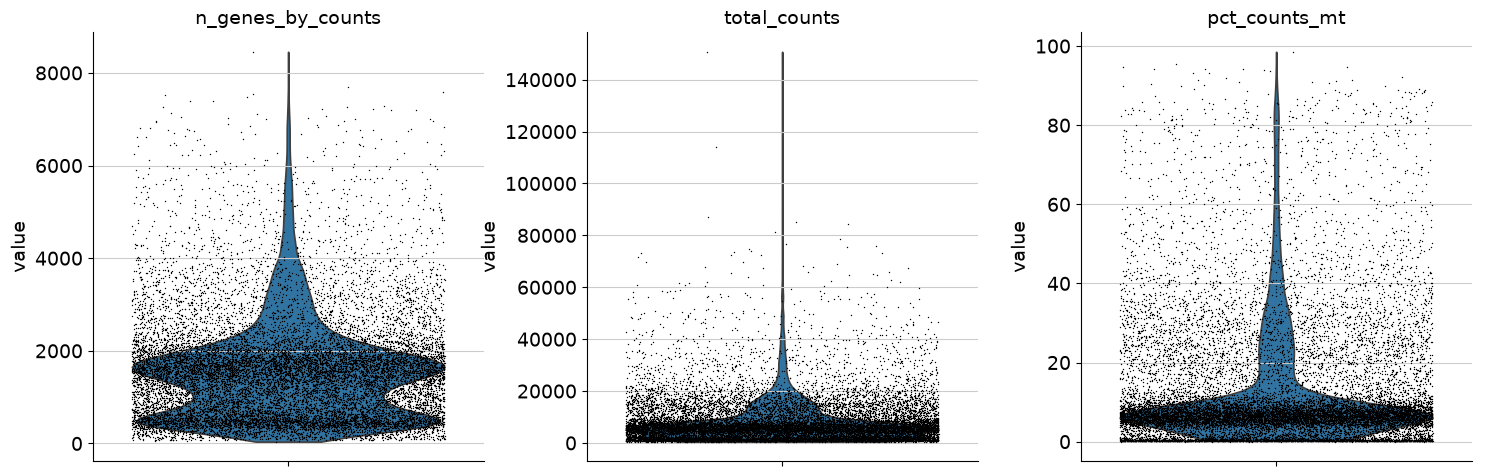

In [14]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
) # pl: plotting